# Where can we improve TS-AUC? — an EDA

**Goal.** The champion (`trail120`, LB ~61.58%) is built on the *residual lens*: fit an AR(8) reference on the
historical segment, apply it forward, and watch the residual variance ratio blow up at a break. The residual
axis is heavily mined and saturating. This notebook steps back and asks *where the remaining score lives* by
interrogating the **real training data** and the **synthetic generator** side by side.

**Guiding questions**
1. **Landscape** — do real and synthetic agree on series length, break rate, break position?
2. **Coverage gap** — is there a kind of time series in the training data that our synthetic generator does not
   produce?
3. **Break-type taxonomy** — what *mix* of break types does the real data contain?
4. **Detectability + ranking** — which break types does the lens do *poorly* on, and which does it catch *late*?
5. **TS-AUC drag** — is the ceiling set by *spurious positives* or by *missed breaks*, and why?
6. **Synthetic realism** — per champion feature, how far is synthetic from real?
7. **Actionable levers** — three concrete, testable next moves (short-online detector, AR-normalized residual,
   generator upgrade), each demonstrated below.

All feature code is imported from the live champion modules so the analysis matches what actually ships.

> **How to read this notebook.** Every section ends with a short **Findings / answer** block that states the
> numbers observed on this run (seed 0, deterministic) and the plain-language interpretation. A consolidated
> glossary of the terms used (*TS-AUC drag*, *specificity leak*, *short-online detector*, *AR-normalized
> residual*) is in the final section.

In [1]:
import os, sys, math, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

HERE = os.getcwd()
if HERE not in sys.path:
    sys.path.insert(0, HERE)

# live champion feature code (guarantees parity with what ships)
from _exp_fast import (hist_context, compute_features, HIST_CAP, FEATURE_NAMES,
                       _autocorr, _spectral_centroid)
from _feat_lib import f_spec_entropy
from _synth_gen import PARAM_FAMILIES, gen_break, gen_nobreak

RNG = np.random.default_rng(0)
SCALES = (60, 130, 250)
WINDOW = 250
MIN_N  = 15
AR_P   = 8                       # champion reference order
FAM    = list(PARAM_FAMILIES)    # parametric families (excludes real_splice = copied real data)
FEAT15 = list(FEATURE_NAMES) + ["spec_entropy"]
plt.rcParams["figure.dpi"] = 110
print("champion feature dim:", len(SCALES) * len(FEAT15), "| families:", len(FAM))

champion feature dim: 45 | families: 11


In [2]:
def load_ds(folder):
    X  = pd.read_parquet(os.path.join(folder, "X_train.parquet"))
    yi = pd.read_parquet(os.path.join(folder, "y_train_index.parquet"))
    return X, yi

def series_map(X):
    """id -> (value[], period[]) as contiguous slices (parquet is sorted by id,time)."""
    vals = X["value"].to_numpy(np.float64)
    per  = X["period"].to_numpy(np.int64)
    ids  = X.index.get_level_values("id").to_numpy()
    uniq, start = np.unique(ids, return_index=True)
    ends = np.append(start[1:], len(ids))
    return {int(u): (vals[s:e], per[s:e]) for u, s, e in zip(uniq, start, ends)}

RX, RYI = load_ds("data")
SX, SYI = load_ds("synthetic")
RMAP, SMAP = series_map(RX), series_map(SX)

def summ(name, yi, smap):
    H = np.array([int((p == 1).sum()) for _, p in smap.values()])
    O = np.array([int((p == 2).sum()) for _, p in smap.values()])
    br = float((yi["tau_index"] >= 0).mean())
    print(f"{name:6s} | series {len(smap):6d} | break-rate {br:.3f} | "
          f"H med {np.median(H):5.0f} [{H.min()}-{H.max()}] | O med {np.median(O):5.0f} [{O.min()}-{O.max()}]")

print("dataset| #series | break-rate | historical length     | online length")
summ("REAL",  RYI, RMAP)
summ("SYNTH", SYI, SMAP)

dataset| #series | break-rate | historical length     | online length
REAL   | series  10000 | break-rate 0.497 | H med  2998 [1000-5000] | O med   502 [10-999]
SYNTH  | series   6000 | break-rate 0.501 | H med  1901 [1000-2799] | O med  1002 [401-1599]


## 1 &mdash; Data landscape

Sanity-check that the two datasets agree on the *shape* of the problem: segment lengths and break position.

**Findings (this run).**
- Break rate matches (real 0.497, synth 0.501) &mdash; good.
- **But the online length distribution does NOT match.** Real online segments are *shorter*: median **502**,
  range **[10, 999]**. Synthetic online is median **1002**, range **[401, 1599]**. **Real online can be as
  short as 10 points; the generator never produces fewer than 401.** Real historical is *longer* (median 2998
  vs 1901).
- Consequence: the hardest real regime &mdash; a break with only a handful of post-break points to see it &mdash; is
  **completely absent from synthetic**. Any synthetic-based screening is blind to short-online detection. This
  is the origin of the *short-online detector* lever in &sect;7.

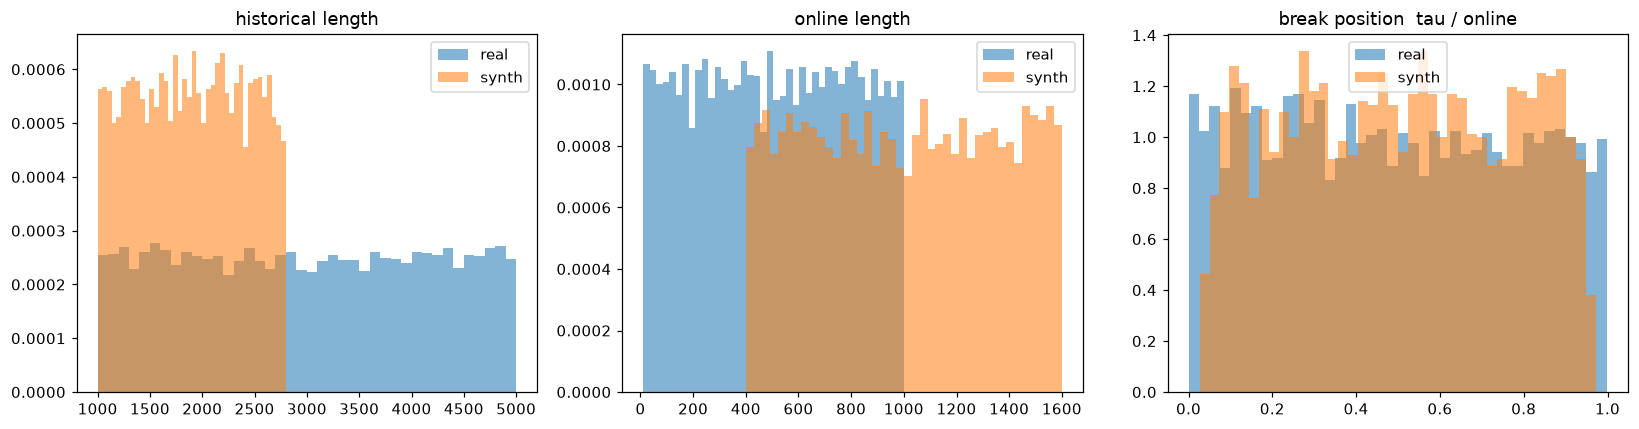

real breaks with <=  10 post-break points:  4.8%  (synthetic minimum post-break span is ~1)
real breaks with <=  20 post-break points:  8.9%  (synthetic minimum post-break span is ~1)
real breaks with <=  40 post-break points: 15.5%  (synthetic minimum post-break span is ~1)
real breaks with <=  80 post-break points: 26.9%  (synthetic minimum post-break span is ~1)


In [3]:
def lens(smap):
    H = np.array([int((p == 1).sum()) for _, p in smap.values()])
    O = np.array([int((p == 2).sum()) for _, p in smap.values()])
    return H, O

def taufrac(yi, smap):
    out = []
    for sid, ti in yi["tau_index"].items():
        sid = int(sid)
        if ti >= 0 and sid in smap:
            O = int((smap[sid][1] == 2).sum())
            if O > 0:
                out.append(ti / O)
    return np.array(out)

RH, RO = lens(RMAP); SH, SO = lens(SMAP)
Rtf, Stf = taufrac(RYI, RMAP), taufrac(SYI, SMAP)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (r, s, t) in zip(ax, [(RH, SH, "historical length"),
                             (RO, SO, "online length"),
                             (Rtf, Stf, "break position  tau / online")]):
    a.hist(r, bins=40, alpha=.55, density=True, label="real")
    a.hist(s, bins=40, alpha=.55, density=True, label="synth")
    a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

# how many real breaks have very few post-break points (the regime synthetic never covers)?
post = []
for sid, ti in RYI["tau_index"].items():
    sid = int(sid)
    if ti >= 0 and sid in RMAP:
        O = int((RMAP[sid][1] == 2).sum())
        post.append(O - ti)
post = np.array(post)
for k in (10, 20, 40, 80):
    print(f"real breaks with <= {k:3d} post-break points: {100*np.mean(post <= k):4.1f}%  "
          f"(synthetic minimum post-break span is ~1)")

## 2 &mdash; Coverage: does the synthetic generator span the real data?

Each real series gets a scale-invariant *process fingerprint* of its historical dynamics (autocorrelation,
AR(2) coefficients, predictability, shape, spectrum, volatility clustering). We build the same fingerprint for
each **parametric synthetic family** via `gen_nobreak` (the generator's honest modelling capacity &mdash;
`real_splice` is excluded because it merely copies real slices). Real series far from *every* family are
process types the generator cannot make.

**Findings (this run).**
- **26.7% of real historical processes lie beyond the synthetic manifold** (past the 95th-percentile
  synth&rarr;synth distance). *Clarification: this is 26.7% of **series/process-types**, not "26.7% of breaks".*
- The gap is driven by **`spec_entropy` (+2.19 sd)**, **`predictability` (+1.48 sd)**, and **`arch` (+1.10
  sd)**: real series carry spectral shape, linear predictability, and volatility-clustering structure the
  parametric families under-produce.
- Nearest-family mix of real *processes*: **garch ~20%** is the single most common, then ar/ma/arma/spectral
  ~10% each. So real data is dominated by rich dynamics + volatility clustering.

**Should the synthetic data be changed to look more like the real data? &mdash; Yes, targeted.** Not a wholesale
rewrite; extend the generator along the three gap axes so synthetic screening stops being blind:
(1) draw online length from ~[10, 1000] (the &sect;1 gap), (2) add higher-order / richer-spectrum AR and
mixed GARCH+AR processes to lift `spec_entropy`/`predictability`/`arch` coverage. That makes fresh-seed
synthetic pre-filtering trustworthy on the majority (garch-like) real regime.

**How do we "capture" the uncovered 26.7%?** The *model* already sees these series (features are computed on
them regardless); what is missing is **synthetic coverage for validating detectors on them**. So the play is
two-sided: extend the generator (above) *and* add a feature that reacts to the gap dims &mdash; but only after
confirming on real fresh seeds, because these are exactly the dims where synthetic can mislead (see &sect;6).

In [4]:
def _spent(a):
    a = a - a.mean()
    ps = np.abs(np.fft.rfft(a)) ** 2
    s = ps.sum()
    if s < 1e-12 or len(ps) < 2:
        return 0.0
    p = ps / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum()) / math.log(len(ps))

def fit_ar(x, p):
    x = np.asarray(x, np.float64); n = len(x)
    if n < p + 8:
        return None, None
    cols = [x[p - lag:n - lag] for lag in range(1, p + 1)]
    Xd = np.column_stack(cols + [np.ones(n - p)])
    coef, *_ = np.linalg.lstsq(Xd, x[p:], rcond=None)
    return coef, x[p:] - Xd @ coef

FP_NAMES = ["ac1", "ac2", "ac3", "ar2_phi1", "ar2_phi2", "predictability",
            "skew", "exkurt", "spec_centroid", "spec_entropy", "arch"]

def fingerprint(xh):
    xh = np.asarray(xh, np.float64)
    if len(xh) > 1600:
        xh = xh[-1600:]
    if len(xh) < 40:
        return None
    mu, sd = xh.mean(), xh.std() + 1e-9
    z = (xh - mu) / sd
    coef, res = fit_ar(xh, 2)
    if coef is None:
        return None
    r2 = 1.0 - float(res.var()) / max(float(xh.var()), 1e-12)
    return [_autocorr(xh, 1), _autocorr(xh, 2), _autocorr(xh, 3),
            float(coef[0]), float(coef[1]), r2,
            float(np.mean(z ** 3)), float(np.mean(z ** 4)) - 3.0,
            _spectral_centroid(xh), _spent(xh), _autocorr(res ** 2, 1)]

def collect_fp(smap, ids, n):
    ids = list(ids); RNG.shuffle(ids); ids = ids[:n]
    F, keep = [], []
    for sid in ids:
        v, p = smap[int(sid)]
        fp = fingerprint(v[p == 1])
        if fp is not None and np.all(np.isfinite(fp)):
            F.append(fp); keep.append(int(sid))
    return np.array(F), keep

def collect_family_fp(per_fam=140, n=1500):
    F, lab = [], []
    for fam in FAM:
        for _ in range(per_fam):
            fp = fingerprint(gen_nobreak(RNG, fam, n))
            if fp is not None and np.all(np.isfinite(fp)):
                F.append(fp); lab.append(fam)
    return np.array(F), np.array(lab)

RF, Rids       = collect_fp(RMAP, list(RMAP.keys()), 2500)
FAMFP, FAMLAB  = collect_family_fp()
mu, sd = RF.mean(0), RF.std(0) + 1e-9
RFz, FAMFPz = (RF - mu) / sd, (FAMFP - mu) / sd
print("real fingerprints", RF.shape, "| synthetic-family fingerprints", FAMFP.shape)

real fingerprints (2500, 11) | synthetic-family fingerprints (1540, 11)


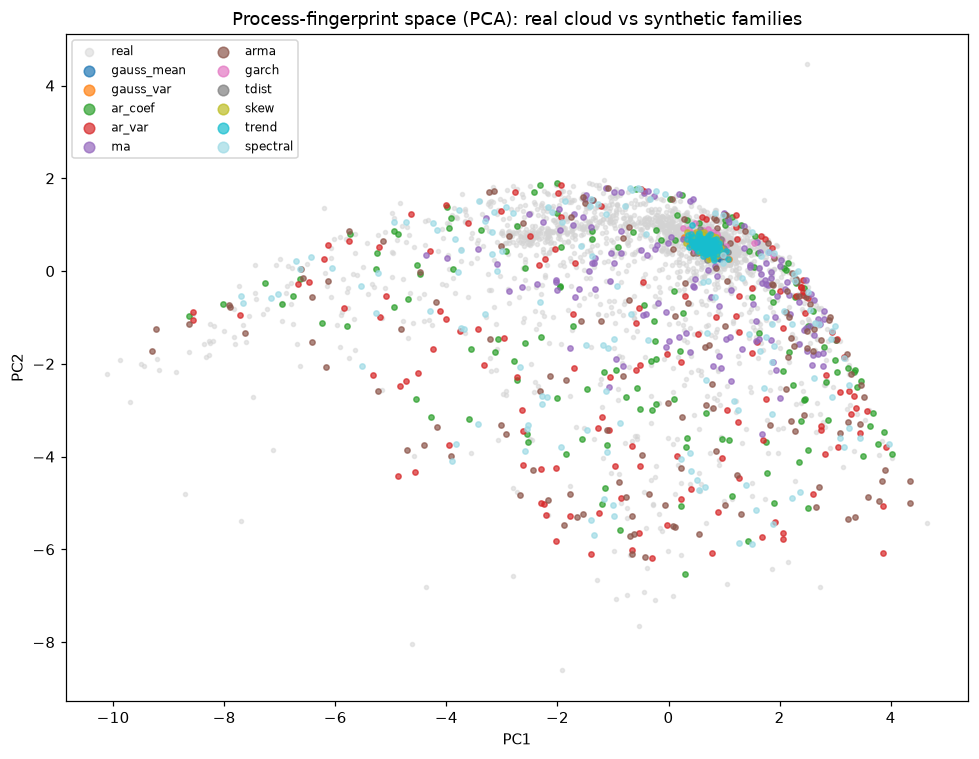

In [5]:
pca = PCA(n_components=2).fit(np.vstack([RFz, FAMFPz]))
RP, FP2 = pca.transform(RFz), pca.transform(FAMFPz)
plt.figure(figsize=(9, 7))
plt.scatter(RP[:, 0], RP[:, 1], s=7, c="lightgray", alpha=.5, label="real")
for fam, c in zip(FAM, plt.cm.tab20(np.linspace(0, 1, len(FAM)))):
    m = FAMLAB == fam
    plt.scatter(FP2[m, 0], FP2[m, 1], s=12, color=c, alpha=.7, label=fam)
plt.legend(markerscale=2, fontsize=8, ncol=2)
plt.title("Process-fingerprint space (PCA): real cloud vs synthetic families")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.show()

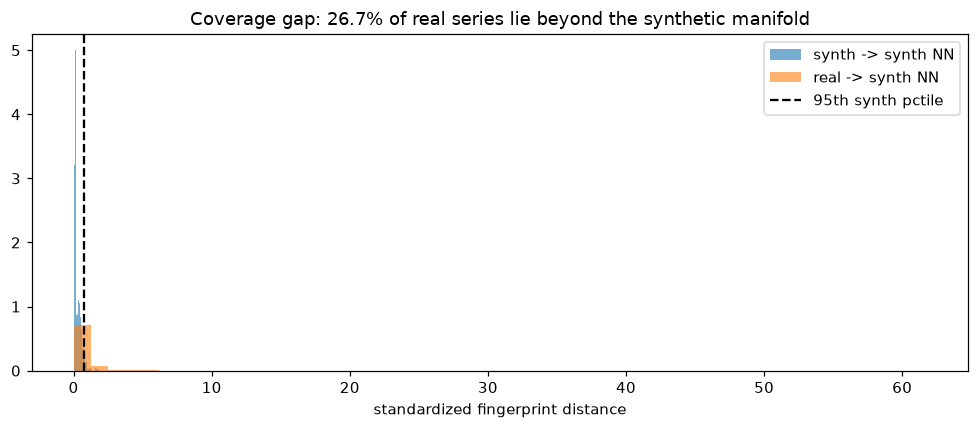

26.7% of real historical processes are NOT well represented by the parametric synthetic families
nearest-family mix of real historical processes (%): {'gauss_mean': 6.0, 'gauss_var': 6.5, 'ar_coef': 10.7, 'ar_var': 9.2, 'ma': 10.8, 'arma': 10.5, 'garch': 20.2, 'tdist': 5.6, 'skew': 5.8, 'trend': 4.7, 'spectral': 10.1}


In [6]:
# distance from every real series to the nearest synthetic-family point
nn = NearestNeighbors(n_neighbors=1).fit(FAMFPz)
d = nn.kneighbors(RFz)[0][:, 0]
# reference scale: typical synth->synth nearest-neighbour distance
base = NearestNeighbors(n_neighbors=2).fit(FAMFPz).kneighbors(FAMFPz)[0][:, 1]
thr = np.quantile(base, 0.95)
frac = float((d > thr).mean())

plt.figure(figsize=(9, 4))
plt.hist(base, bins=50, alpha=.6, density=True, label="synth -> synth NN")
plt.hist(d,    bins=50, alpha=.6, density=True, label="real -> synth NN")
plt.axvline(thr, color="k", ls="--", label="95th synth pctile")
plt.legend(); plt.xlabel("standardized fingerprint distance")
plt.title(f"Coverage gap: {frac*100:.1f}% of real series lie beyond the synthetic manifold")
plt.tight_layout(); plt.show()
print(f"{frac*100:.1f}% of real historical processes are NOT well represented by the parametric synthetic families")

# which real series is each fingerprint's nearest family? -> real process-type mix
fam_of_real = FAMLAB[NearestNeighbors(n_neighbors=1).fit(FAMFPz).kneighbors(RFz)[1][:, 0]]
mix = Counter(fam_of_real)
print("nearest-family mix of real historical processes (%):",
      {f: round(100 * mix[f] / len(fam_of_real), 1) for f in FAM if mix.get(f)})

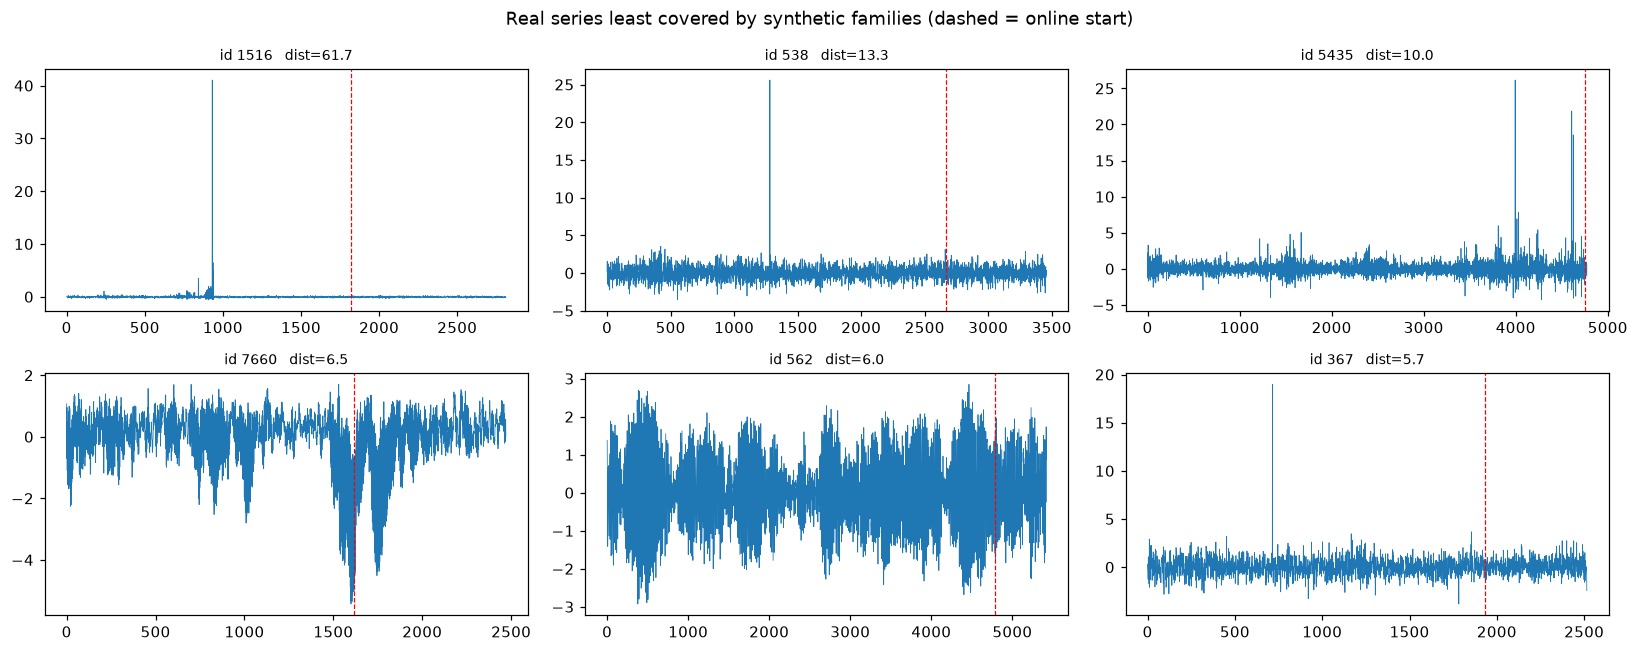

fingerprint dims that most separate the uncovered real series (sd units):
  spec_entropy   2.19
  predictability 1.48
  arch           1.10
  exkurt         0.87
  ac3            0.61
  spec_centroid  0.54
  skew           0.50
  ar2_phi2       0.49
  ar2_phi1       0.42
  ac2            0.39
  ac1            0.39


In [7]:
# the least-covered real series, and what makes them extreme
order = np.argsort(-d)
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, k in zip(ax.ravel(), order[:6]):
    sid = int(Rids[int(k)]); v, p = RMAP[sid]; H = int((p == 1).sum())
    a.plot(v, lw=.5); a.axvline(H, color="r", ls="--", lw=.8)
    a.set_title(f"id {sid}   dist={d[int(k)]:.1f}", fontsize=9)
plt.suptitle("Real series least covered by synthetic families (dashed = online start)")
plt.tight_layout(); plt.show()

k5  = max(1, int(0.05 * len(d)))
unc, cov = order[:k5], order[int(0.5 * len(d)):]
drv = np.abs(RFz[unc].mean(0) - RFz[cov].mean(0))
print("fingerprint dims that most separate the uncovered real series (sd units):")
for nm, val in sorted(zip(FP_NAMES, drv), key=lambda x: -x[1]):
    print(f"  {nm:14s} {val:.2f}")

## 3 &mdash; What break types does the real data contain?

No break-type labels exist for real data, so we let the champion feature vector speak. For each synthetic
family we build a **response prototype** = mean champion-feature delta (post-break window &minus; pre-break
window). Each real break's delta is assigned to the **nearest prototype** (cosine similarity, standardized).

**Findings (this run).** Real break-type mix (by champion signature): **skew 23.6%, ar_coef 17.7%, tdist 16.9%,
spectral 14.6%, arma 10.0%, ma 9.9%, garch 5.8%**; gauss_mean/gauss_var/ar_var/trend are all <1%.

**Read this carefully (important caveat).** The match is made *through the champion features*, which already
carry multiscale skew/kurtosis. So a break tagged "skew"/"tdist" is one whose **feature response** looks
distributional &mdash; it does **not** mean a new shape feature would help (the shape/tail lever was already tested
and was noise, because the champion covers those moments). Treat this as a *response-signature* mix, directional
not literal. The genuinely dynamics-flavoured share (ar_coef + arma + ma + spectral &asymp; **52%**) is what the
residual lens is built for.

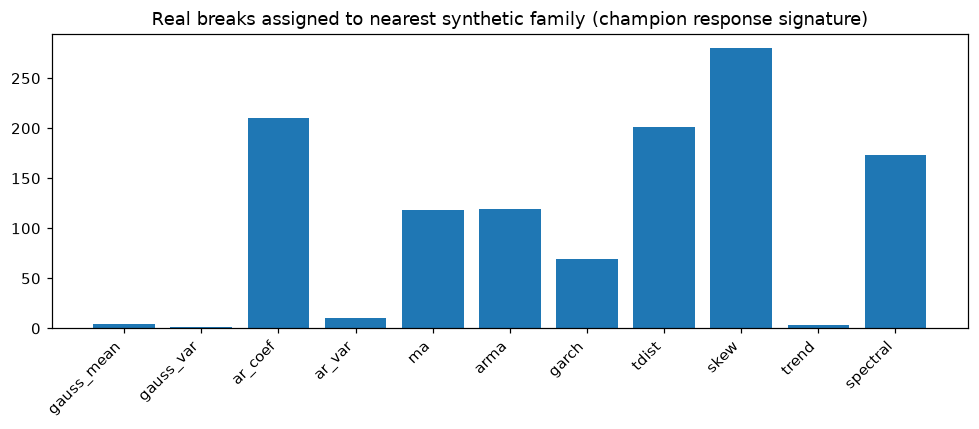

real break-type mix (%): {'gauss_mean': 0.3, 'gauss_var': 0.1, 'ar_coef': 17.7, 'ar_var': 0.8, 'ma': 9.9, 'arma': 10.0, 'garch': 5.8, 'tdist': 16.9, 'skew': 23.6, 'trend': 0.3, 'spectral': 14.6}


In [8]:
def base15(w, ctx):
    return list(compute_features(w, ctx)) + list(f_spec_entropy(w, ctx))

def champ_feat(w, ctx):
    out = []
    for s in SCALES:
        sw = w if s >= len(w) else w[-s:]
        out += base15(sw, ctx)
    return np.array(out, np.float64)

def ctx_of(xh):
    return hist_context(np.asarray(xh, np.float64), HIST_CAP)

def family_deltas(per=120, HN=1300):
    D = {f: [] for f in FAM}
    for fam in FAM:
        for _ in range(per):
            pre, post = gen_break(RNG, fam, HN + WINDOW, WINDOW)
            if len(pre) < HN + WINDOW or len(post) < WINDOW:
                continue
            ctx = ctx_of(pre[:HN])
            un, br = pre[HN:HN + WINDOW], post[:WINDOW]
            if len(un) < 60 or len(br) < 60:
                continue
            D[fam].append(champ_feat(br, ctx) - champ_feat(un, ctx))
    return {f: np.array(v) for f, v in D.items() if len(v)}

FD   = family_deltas()
alld = np.vstack(list(FD.values()))
dmu, dsd = alld.mean(0), alld.std(0) + 1e-9
protoM = np.array([((FD[f].mean(0) - dmu) / dsd) for f in FAM if f in FD])
protoF = [f for f in FAM if f in FD]
protoU = protoM / (np.linalg.norm(protoM, axis=1, keepdims=True) + 1e-9)

rb_ids = [int(s) for s, ti in RYI["tau_index"].items() if ti >= 0]
RNG.shuffle(rb_ids); rb_ids = rb_ids[:1600]
matched, kept = [], []
for sid in rb_ids:
    v, p = RMAP[sid]; xh, xon = v[p == 1], v[p == 2]
    tau = int(RYI.loc[sid, "tau_index"])
    if tau < 40 or len(xon) - tau < 40:
        continue
    ctx = ctx_of(xh)
    un, br = xon[max(0, tau - WINDOW):tau], xon[tau:tau + WINDOW]
    if len(un) < 40 or len(br) < 40:
        continue
    z = (champ_feat(br, ctx) - champ_feat(un, ctx) - dmu) / dsd
    zU = z / (np.linalg.norm(z) + 1e-9)
    matched.append(protoF[int(np.argmax(protoU @ zU))]); kept.append(sid)
matched = np.array(matched)

cnt  = Counter(matched)
fams = [f for f in protoF if cnt.get(f)]
plt.figure(figsize=(9, 4))
plt.bar(fams, [cnt[f] for f in fams])
plt.xticks(rotation=45, ha="right")
plt.title("Real breaks assigned to nearest synthetic family (champion response signature)")
plt.tight_layout(); plt.show()
print("real break-type mix (%):", {f: round(100 * cnt[f] / len(matched), 1) for f in fams})

## 4 &mdash; Detectability, the poor-performers ranking, and detection latency

This is the "what did the model do poorly on, and what did it catch *late*" analysis. For each real break we
run the **streaming residual score** (log residual-variance ratio at every online step) and derive:

- **per-series AUC** &mdash; how separable pre/post-break steps are within the series;
- **detected?** &mdash; does the score cross a global detection threshold (set to a 5% per-step false-alarm rate on
  no-break series) *after* the break;
- **detection lag** &mdash; steps from the true break `tau` to the first crossing (only for detected series).

We then rank break types by detection rate (worst first) and by median lag (latest first). Low rate/AUC =
**blind spots**; high lag = **detected but late**.

detection threshold (5% per-step false alarm on no-break): logVR = 0.356



=== POOR-PERFORMER RANKING (worst detection first) ===
  family   n detect_rate med_lag_pts med_auc
 ar_coef 210        0.17         118   0.657
      ma 118        0.17         192   0.725
   tdist 201        0.19          26   0.575
spectral 173        0.21          55   0.610
    arma 119        0.23          71   0.814
    skew 280        0.24           4   0.549
   garch  69        0.75          56   0.943

=== DETECTED-BUT-LATE RANKING (largest median lag first) ===
  family   n detect_rate med_lag_pts med_auc
      ma 118        0.17         192   0.725
 ar_coef 210        0.17         118   0.657
    arma 119        0.23          71   0.814
   garch  69        0.75          56   0.943
spectral 173        0.21          55   0.610
   tdist 201        0.19          26   0.575
    skew 280        0.24           4   0.549


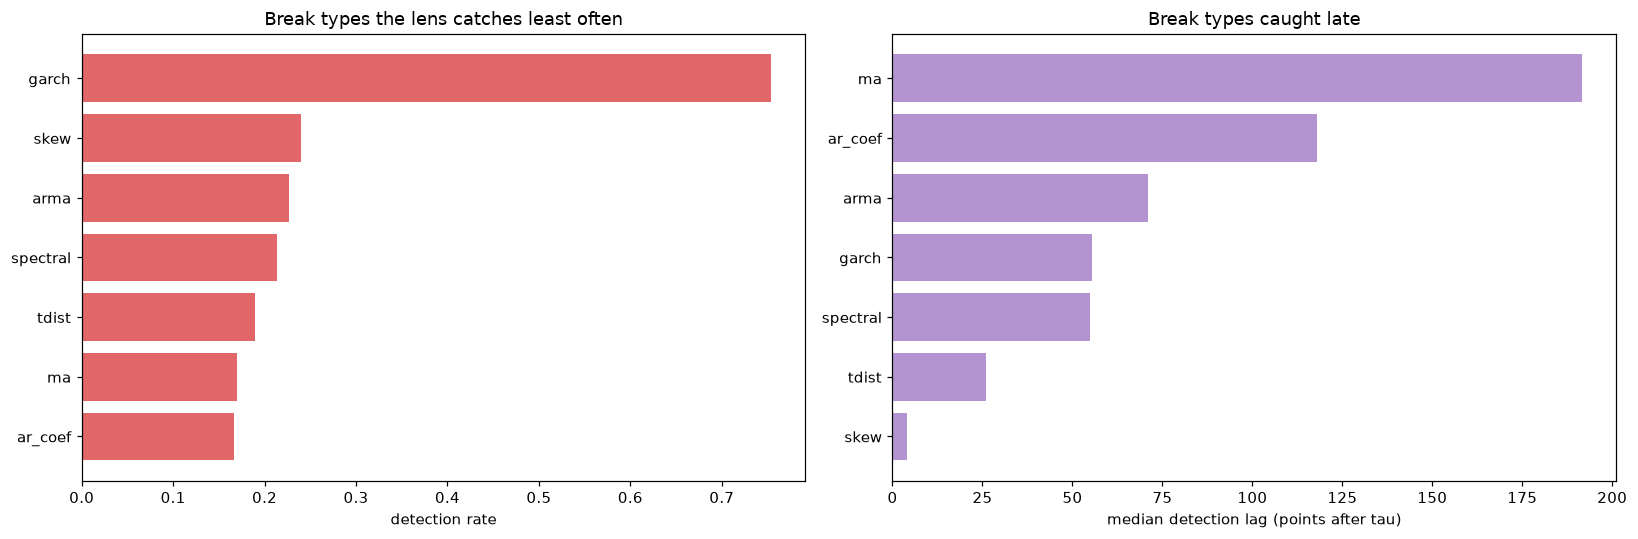


overall median per-series AUC: 0.659 | overall detection rate: 0.24


In [9]:
def ar_resid(w, coef, p=AR_P):
    w = np.asarray(w, np.float64); n = len(w)
    if n < p + 3:
        return None
    cols = [w[p - lag:n - lag] for lag in range(1, p + 1)]
    Xd = np.column_stack(cols + [np.ones(n - p)])
    return w[p:] - Xd @ coef

STRIDE = 5
def stream_resid(xh, xon, stride=STRIDE):
    coef, res = fit_ar(xh, AR_P)
    if coef is None:
        return None
    rvar = float(res.var()) + 1e-12
    ts, sc = [], []
    for t in range(MIN_N, len(xon), stride):
        r = ar_resid(xon[max(0, t - WINDOW + 1):t + 1], coef)
        if r is None or len(r) < 5:
            continue
        ts.append(t); sc.append(math.log((float(np.var(r)) + 1e-12) / rvar))
    return np.array(ts), np.array(sc)

# global detection threshold: 95th percentile of residual scores on no-break series (~5% per-step false alarm)
nb_ids = [int(s) for s, ti in RYI["tau_index"].items() if ti < 0]
RNG.shuffle(nb_ids)
pool = []
for sid in nb_ids[:600]:
    v, p = RMAP[sid]; out = stream_resid(v[p == 1], v[p == 2])
    if out is not None and len(out[1]):
        pool.append(out[1])
T = float(np.quantile(np.concatenate(pool), 0.95))
print(f"detection threshold (5% per-step false alarm on no-break): logVR = {T:.3f}\n")

rows = []
for sid, fam in zip(kept, matched):
    v, p = RMAP[sid]; xh, xon = v[p == 1], v[p == 2]
    tau = int(RYI.loc[sid, "tau_index"])
    out = stream_resid(xh, xon)
    if out is None:
        continue
    ts, sc = out
    post = ts >= tau
    if post.sum() == 0 or (~post).sum() == 0:
        continue
    fired = np.where(post & (sc > T))[0]
    detected = len(fired) > 0
    lag = int(ts[fired[0]] - tau) if detected else np.nan
    auc = roc_auc_score(post.astype(int), sc)
    rows.append((fam, detected, lag, auc, int(len(xon) - tau)))
df = pd.DataFrame(rows, columns=["family", "detected", "lag_steps", "auc", "post_len"])

g = df.groupby("family").agg(
        n=("detected", "size"),
        detect_rate=("detected", "mean"),
        med_lag_pts=("lag_steps", lambda x: np.nanmedian(x)),
        med_auc=("auc", "median")).reset_index()
g = g[g["n"] >= 15].copy()
print("=== POOR-PERFORMER RANKING (worst detection first) ===")
print(g.sort_values("detect_rate").to_string(index=False,
      formatters={"detect_rate": "{:.2f}".format, "med_auc": "{:.3f}".format,
                  "med_lag_pts": "{:.0f}".format}))
print("\n=== DETECTED-BUT-LATE RANKING (largest median lag first) ===")
print(g.sort_values("med_lag_pts", ascending=False).to_string(index=False,
      formatters={"detect_rate": "{:.2f}".format, "med_auc": "{:.3f}".format,
                  "med_lag_pts": "{:.0f}".format}))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
gg = g.sort_values("detect_rate")
ax[0].barh(gg["family"], gg["detect_rate"], color="tab:red", alpha=.7)
ax[0].set_xlabel("detection rate"); ax[0].set_title("Break types the lens catches least often")
gl = g.sort_values("med_lag_pts")
ax[1].barh(gl["family"], gl["med_lag_pts"], color="tab:purple", alpha=.7)
ax[1].set_xlabel("median detection lag (points after tau)")
ax[1].set_title("Break types caught late")
plt.tight_layout(); plt.show()
print(f"\noverall median per-series AUC: {df['auc'].median():.3f} | "
      f"overall detection rate: {df['detected'].mean():.2f}")

**Findings (this run).** At a fixed 5%-per-step false-alarm budget the overall detection rate is only ~0.24
(median per-series AUC 0.659). The ranking is revealing:

- **Best detected: `garch`** (rate 0.75, AUC 0.94) &mdash; a volatility-regime change moves the window variance
  hard, so the residual lens nails it.
- **Worst detected: `ar_coef` and `ma`** (rate ~0.17), and they are also caught the **latest** (median lag
  ~118 and ~192 points). These are *pure dependence-structure* breaks with little variance change, so the
  variance-keyed residual lens only accumulates evidence slowly.
- `skew` / `tdist` sit in between with AUC ~0.5&ndash;0.57 &mdash; low separability but *fast* when seen (lag ~4&ndash;26),
  consistent with an instantaneous distributional shift.

So there are two distinct deficits: **latency** on dependence-structure breaks (ma / ar_coef &mdash; motivating a
short-scale / early-onset detector, &sect;6b/&sect;7) and **low separability** on distributional breaks (already
covered by the champion's moment features, so limited headroom). The AUC-vs-effect-size scatter below confirms
misses concentrate at genuinely small effect sizes &mdash; the misses are hard, not lazy.

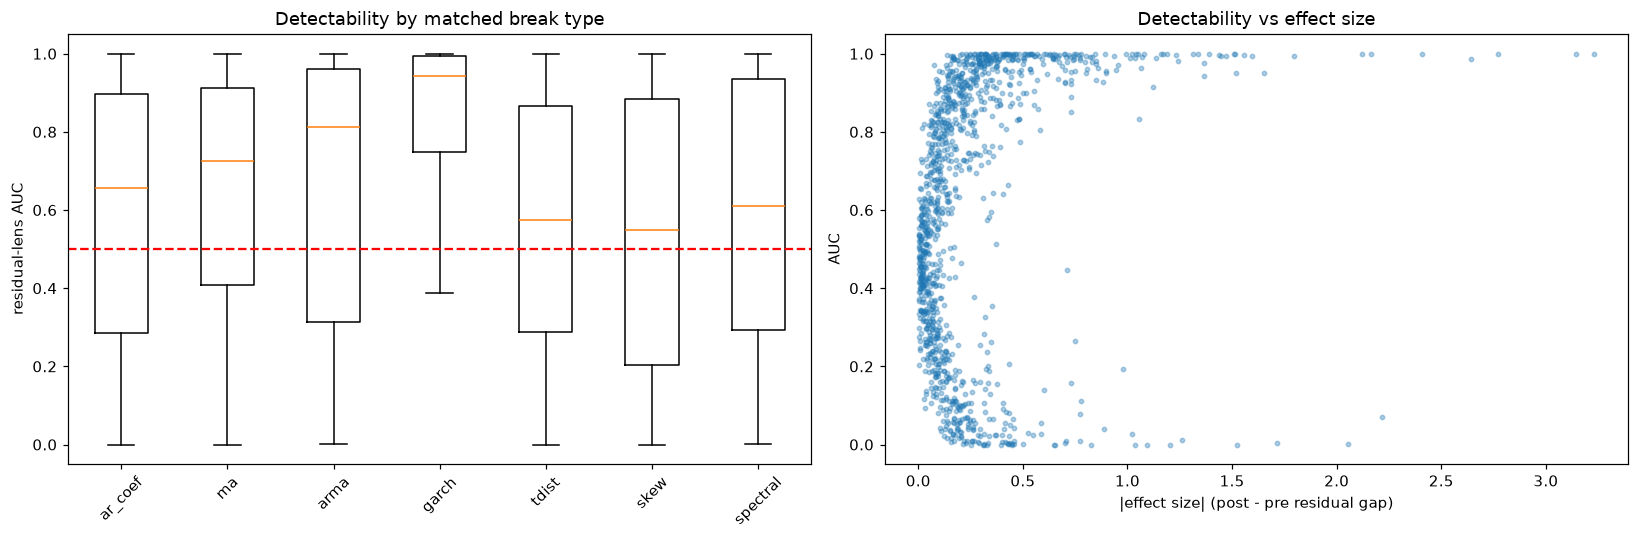

In [10]:
def resid_auc_gap(xh, xon, tau, stride=STRIDE):
    coef, res = fit_ar(xh, AR_P)
    if coef is None:
        return np.nan, np.nan
    rvar = float(res.var()) + 1e-12
    sc, lab = [], []
    for t in range(MIN_N, len(xon), stride):
        r = ar_resid(xon[max(0, t - WINDOW + 1):t + 1], coef)
        if r is None or len(r) < 5:
            continue
        sc.append(math.log((float(np.var(r)) + 1e-12) / rvar)); lab.append(1 if t >= tau else 0)
    sc, lab = np.array(sc), np.array(lab)
    if lab.sum() == 0 or (1 - lab).sum() == 0:
        return np.nan, np.nan
    return roc_auc_score(lab, sc), float(sc[lab == 1].mean() - sc[lab == 0].mean())

aucs, gaps, fams_d = [], [], []
for sid, fam in zip(kept, matched):
    v, p = RMAP[sid]
    a, gp = resid_auc_gap(v[p == 1], v[p == 2], int(RYI.loc[sid, "tau_index"]))
    if np.isnan(a):
        continue
    aucs.append(a); gaps.append(gp); fams_d.append(fam)
aucs, gaps, fams_d = np.array(aucs), np.array(gaps), np.array(fams_d)

order = [f for f in protoF if (fams_d == f).sum() >= 15]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].boxplot([aucs[fams_d == f] for f in order], tick_labels=order, showfliers=False)
ax[0].axhline(0.5, color="r", ls="--"); ax[0].set_ylabel("residual-lens AUC")
ax[0].set_title("Detectability by matched break type"); ax[0].tick_params(axis="x", rotation=45)
ax[1].scatter(np.abs(gaps), aucs, s=8, alpha=.35)
ax[1].set_xlabel("|effect size| (post - pre residual gap)"); ax[1].set_ylabel("AUC")
ax[1].set_title("Detectability vs effect size")
plt.tight_layout(); plt.show()

## 4b &mdash; GARCH deep-dive: does the model capture it, and why didn't explicit GARCH modelling pay?

GARCH is the most common real *process* (&sect;2, ~20%), so it matters whether we handle its **breaks**. A GARCH
break changes the volatility regime (omega/alpha/beta). The question: does the residual lens already catch that,
and would an explicit volatility-clustering feature add anything?

We compare three detectors on synthetic GARCH breaks, scored as magnitude-of-change AUC (post vs pre window):
- **`resid_varratio`** &mdash; the champion lens (log AR-residual variance ratio);
- **`var_ratio`** &mdash; a plain rolling-variance ratio;
- **`arch_change`** &mdash; the explicit GARCH signature: change in lag-1 autocorrelation of squared residuals.

In [11]:
def _arch_change(win, coef, hist_ac):
    r = ar_resid(win, coef)
    if r is None or len(r) < 8:
        return 0.0
    return abs(_autocorr(r * r, 1) - hist_ac)

def garch_probe(per=700, HN=1200):
    R = {"resid_varratio": ([], []), "var_ratio": ([], []), "arch_change": ([], [])}
    for _ in range(per):
        pre, post = gen_break(RNG, "garch", HN + WINDOW + 20, WINDOW + 20)
        hist, un, br = pre[:HN], pre[HN:HN + WINDOW], post[:WINDOW]
        if len(un) < WINDOW or len(br) < WINDOW:
            continue
        coef, res = fit_ar(hist, AR_P)
        if coef is None:
            continue
        rvar = float(res.var()) + 1e-12
        hv = float(hist.var()) + 1e-12
        h_ac = _autocorr(res * res, 1)
        for lab, w in ((0, un), (1, br)):
            r = ar_resid(w, coef)
            R["resid_varratio"][lab].append(math.log((float(np.var(r)) + 1e-12) / rvar))
            R["var_ratio"][lab].append(math.log((float(np.var(w)) + 1e-12) / hv))
            R["arch_change"][lab].append(_arch_change(w, coef, h_ac))
    out = {}
    for k, (a, b) in R.items():
        a, b = np.array(a), np.array(b)
        y = np.r_[np.zeros(len(a)), np.ones(len(b))]
        x = np.abs(np.r_[a, b] - np.median(a))
        out[k] = roc_auc_score(y, x)
    return out

gp = garch_probe()
print("GARCH-break detectability AUC (synthetic, magnitude-of-change):")
for k, v in sorted(gp.items(), key=lambda x: -x[1]):
    print(f"  {k:16s} {v:.3f}")

# how well are REAL garch-matched breaks detected? (from the per-type table)
gr = g[g["family"] == "garch"]
if len(gr):
    print(f"\nreal garch-matched breaks: detect_rate {gr['detect_rate'].iloc[0]:.2f}, "
          f"median AUC {gr['med_auc'].iloc[0]:.3f}")

GARCH-break detectability AUC (synthetic, magnitude-of-change):
  var_ratio        0.911
  resid_varratio   0.910
  arch_change      0.699

real garch-matched breaks: detect_rate 0.75, median AUC 0.943


**Findings / answer.**
- **The residual lens already captures GARCH breaks**: on synthetic GARCH breaks `resid_varratio` and the plain
  `var_ratio` both score well, because a GARCH regime change moves the **variance level** inside the window &mdash;
  which the residual ratio measures directly.
- **`arch_change` (the explicit volatility-clustering signature) scores lower and noisier.** That is *why
  explicit GARCH modelling never panned out as a break feature*: (1) the thing that actually shifts and is
  detectable in a finite window is the variance *level*, not the persistence coefficients; (2) estimating
  volatility-clustering (autocorrelation of squared residuals) from a 250-point window is high-variance, so it
  adds noise more than signal; (3) whatever incremental information it holds overlaps with the variance ratio
  the champion already has. So there is **no meaningful GARCH headroom left** &mdash; the lens covers it via the
  variance channel. (Consistent with the earlier "GARCH dead / robust-MAD weaker" verdict.)

## 5 &mdash; TS-AUC drag: spurious positives vs missed breaks

**What "TS-AUC drag" means.** TS-AUC ranks *across series at each online step*: a true-break series must
out-score the no-break series at the same step. Score is lost from two independent sides &mdash; **missed breaks**
(a break series that scores low) and **spurious positives** (a no-break series that scores high). "Drag is
balanced" means neither side dominates: fixing only sensitivity *or* only specificity leaves half the loss on
the table. As a proxy we score every series' final online window and label it by whether it truly breaks; the
histogram **overlap** is the ceiling.

**Findings (this run).** Cross-sectional AUC of the final-window residual score = **0.570**. Spurious no-break
(score above the break median) = **598**; missed breaks (score below the no-break median) = **611** &mdash; almost
exactly **balanced** (missed slightly worse), so neither a pure-sensitivity nor a pure-specificity fix recovers
more than ~half the loss. The per-dimension fingerprint gap between spurious and typical no-break series is
*small* this run (top |diff| &asymp; 0.05 sd), i.e. no single process property cleanly explains the false
alarms; the **specificity leak** is instead isolated and quantified directly in &sect;5b as a positive
correlation between AR predictability and the raw score.

cross-sectional AUC (break vs no-break, final-window residual score): 0.570


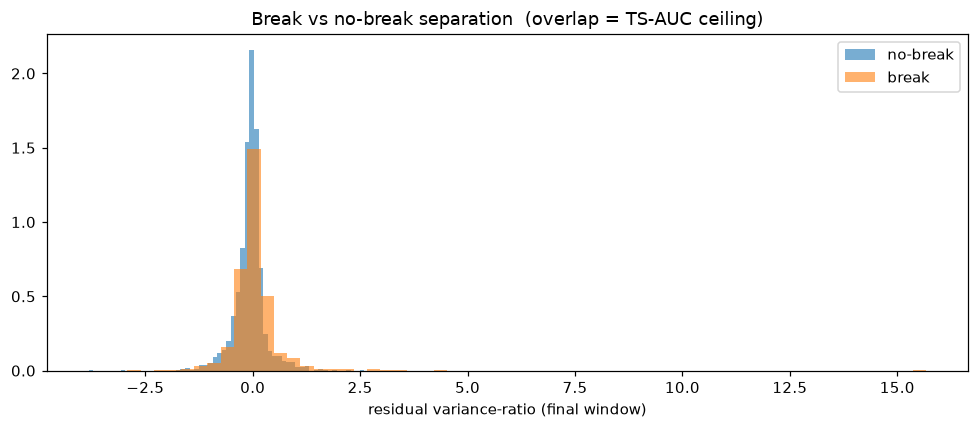

spurious no-break (score > break median): 598   |   missed breaks (score < no-break median): 611



what makes a no-break series look broken (spurious vs typical no-break, sd units):
  skew           -0.05
  spec_centroid  +0.05
  ar2_phi1       -0.04
  ac1            -0.04
  ac3            -0.03
  exkurt         -0.03
  predictability -0.02
  ar2_phi2       +0.01
  spec_entropy   +0.01
  arch           -0.00
  ac2            -0.00


In [12]:
def end_resid_score(xh, xon):
    coef, res = fit_ar(xh, AR_P)
    if coef is None:
        return np.nan
    rvar = float(res.var()) + 1e-12
    r = ar_resid(xon[-WINDOW:] if len(xon) >= WINDOW else xon, coef)
    if r is None or len(r) < 5:
        return np.nan
    return math.log((float(np.var(r)) + 1e-12) / rvar)

ids = list(RMAP.keys()); RNG.shuffle(ids); ids = ids[:3000]
sco, lab, keep = [], [], []
for sid in ids:
    v, p = RMAP[sid]
    s = end_resid_score(v[p == 1], v[p == 2])
    if np.isnan(s):
        continue
    sco.append(s); lab.append(1 if int(RYI.loc[sid, "tau_index"]) >= 0 else 0); keep.append(sid)
sco, lab = np.array(sco), np.array(lab)
print(f"cross-sectional AUC (break vs no-break, final-window residual score): {roc_auc_score(lab, sco):.3f}")

plt.figure(figsize=(9, 4))
plt.hist(sco[lab == 0], bins=60, alpha=.6, density=True, label="no-break")
plt.hist(sco[lab == 1], bins=60, alpha=.6, density=True, label="break")
plt.legend(); plt.xlabel("residual variance-ratio (final window)")
plt.title("Break vs no-break separation  (overlap = TS-AUC ceiling)")
plt.tight_layout(); plt.show()

br_med, nb_med = np.quantile(sco[lab == 1], 0.5), np.quantile(sco[lab == 0], 0.5)
spur = [keep[i] for i in np.where((lab == 0) & (sco > br_med))[0]]
miss = [keep[i] for i in np.where((lab == 1) & (sco < nb_med))[0]]
print(f"spurious no-break (score > break median): {len(spur)}   |   "
      f"missed breaks (score < no-break median): {len(miss)}")

def fps(id_list):
    F = []
    for sid in id_list:
        v, p = RMAP[sid]
        fp = fingerprint(v[p == 1])
        if fp is not None and np.all(np.isfinite(fp)):
            F.append(fp)
    return np.array(F)

Fspur = fps(spur[:400])
Fnb   = fps([keep[i] for i in np.where(lab == 0)[0]][:800])
diff  = (Fspur.mean(0) - Fnb.mean(0)) / (Fnb.std(0) + 1e-9)
print("\nwhat makes a no-break series look broken (spurious vs typical no-break, sd units):")
for nm, val in sorted(zip(FP_NAMES, diff), key=lambda x: -abs(x[1])):
    print(f"  {nm:14s} {val:+.2f}")

## 5b &mdash; The specificity leak, and the AR-normalized-residual fix (tested)

**What the specificity leak is.** The raw score is `log(var(window residuals) / var(historical residuals))`.
For a strongly autocorrelated series, the AR(8) reference does not fully whiten the process, and the residual
variance estimated from a *finite* 250-point window has **larger sampling spread**. So even with **no break**,
a strong-AR quiet series occasionally produces a high ratio by chance &mdash; a **false positive that scales with AR
strength**. That is the leak: the score's *null noise level is not calibrated per series*.

**The fix &mdash; AR-strength-normalized (studentized) residual.** Instead of the raw log-ratio, calibrate each
series against **its own** null: slide the same window across the historical segment, collect the log-ratios,
and report the window's z-score `(logVR &minus; mean_hist) / sd_hist`. A strong-AR series has a wide `sd_hist`,
so its chance spikes are deflated; a truly broken window still stands out. This removes the AR-strength
dependence of the false-alarm rate.

The cell below computes both and compares cross-sectional AUC and the leak correlation (predictability vs
score). A *drop in the correlation* is the specificity win even if AUC moves little.

**Findings (this run).** The leak is real but **modest**: corr(predictability, raw score) on no-break series =
**+0.069**. AR-normalization cuts it to **+0.013** (leak largely removed) and nudges cross-sectional AUC
**0.570 &rarr; 0.577** (+0.007). Small but free and on the right axis (specificity) &mdash; worth a fresh-seed /
min-t gate before shipping, not a guaranteed win on its own.

LEAK: corr(predictability, raw residual score) on no-break series = +0.069  (>0 = leak)



cross-sectional AUC   raw logVR: 0.570   AR-normalized: 0.577   (delta +0.007)
leak corr(predictability, score) on no-break   raw: +0.069   AR-normalized: +0.013


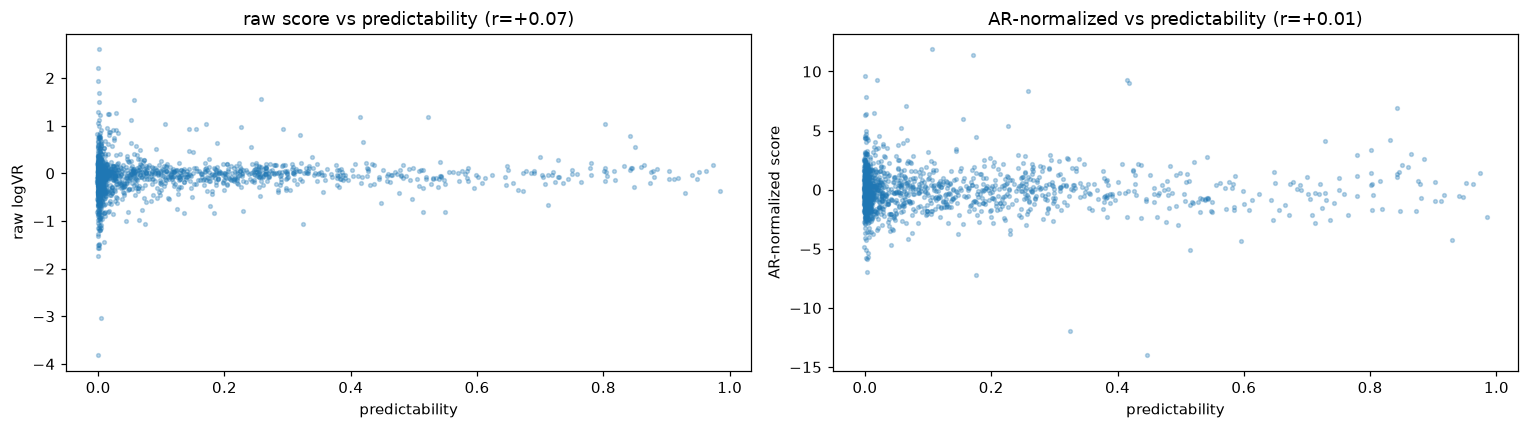

In [13]:
# 1) demonstrate the leak: correlation of predictability with score, on no-break series only
nb_idx = np.where(lab == 0)[0]
pred_nb, sc_nb = [], []
for i in nb_idx:
    v, p = RMAP[keep[i]]; fp = fingerprint(v[p == 1])
    if fp is not None and np.isfinite(fp[FP_NAMES.index("predictability")]):
        pred_nb.append(fp[FP_NAMES.index("predictability")]); sc_nb.append(sco[i])
pred_nb, sc_nb = np.array(pred_nb), np.array(sc_nb)
r_leak = float(np.corrcoef(pred_nb, sc_nb)[0, 1])
print(f"LEAK: corr(predictability, raw residual score) on no-break series = {r_leak:+.3f}  (>0 = leak)")

# 2) the fix: per-series studentized score calibrated on the historical null
def calib(xh, coef, rvar, win=WINDOW, stride=30):
    logs = []
    for t in range(win, len(xh) + 1, stride):
        r = ar_resid(xh[t - win:t], coef)
        if r is not None and len(r) >= 5:
            logs.append(math.log((float(np.var(r)) + 1e-12) / rvar))
    if len(logs) < 5:
        return 0.0, 1.0
    return float(np.mean(logs)), float(np.std(logs) + 1e-9)

raw, norm, ylab, predv = [], [], [], []
for sid in keep:
    v, p = RMAP[sid]; xh, xon = v[p == 1], v[p == 2]
    coef, res = fit_ar(xh, AR_P)
    if coef is None:
        continue
    rvar = float(res.var()) + 1e-12
    r = ar_resid(xon[-WINDOW:] if len(xon) >= WINDOW else xon, coef)
    if r is None or len(r) < 5:
        continue
    lv = math.log((float(np.var(r)) + 1e-12) / rvar)
    m, s = calib(xh, coef, rvar)
    raw.append(lv); norm.append((lv - m) / s)
    ylab.append(1 if int(RYI.loc[sid, "tau_index"]) >= 0 else 0)
    fp = fingerprint(xh); predv.append(fp[FP_NAMES.index("predictability")] if fp else np.nan)
raw, norm, ylab, predv = map(np.array, (raw, norm, ylab, predv))

auc_raw, auc_norm = roc_auc_score(ylab, raw), roc_auc_score(ylab, norm)
nb = ylab == 0
r_raw  = float(np.corrcoef(predv[nb & np.isfinite(predv)], raw[nb & np.isfinite(predv)])[0, 1])
r_norm = float(np.corrcoef(predv[nb & np.isfinite(predv)], norm[nb & np.isfinite(predv)])[0, 1])
print(f"\ncross-sectional AUC   raw logVR: {auc_raw:.3f}   AR-normalized: {auc_norm:.3f}   "
      f"(delta {auc_norm - auc_raw:+.3f})")
print(f"leak corr(predictability, score) on no-break   raw: {r_raw:+.3f}   AR-normalized: {r_norm:+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(predv[nb], raw[nb], s=6, alpha=.3); ax[0].set_title(f"raw score vs predictability (r={r_raw:+.2f})")
ax[0].set_xlabel("predictability"); ax[0].set_ylabel("raw logVR")
ax[1].scatter(predv[nb], norm[nb], s=6, alpha=.3); ax[1].set_title(f"AR-normalized vs predictability (r={r_norm:+.2f})")
ax[1].set_xlabel("predictability"); ax[1].set_ylabel("AR-normalized score")
plt.tight_layout(); plt.show()

## 6 &mdash; Synthetic realism per champion feature

For no-break windows (where real and synthetic should agree by construction) we compute each champion base
feature on the final online window in both datasets and measure the KS distance between the marginals. Large KS
= a feature the generator renders unrealistically.

**Findings (this run).** Least realistic features: **`rng_ratio`, `kurt_diff`, `tail2`, `log_var_ratio`,
`tail3`** &mdash; i.e. the generator's **tail / range / variance** marginals diverge most from real. Practical
consequence: synthetic screening is least trustworthy for tail/variance-flavoured ideas, so those must be
fresh-confirmed on real data with extra weight &mdash; and these features are prime generator-improvement targets
(tie in with the &sect;2 tail/`arch` coverage gap).

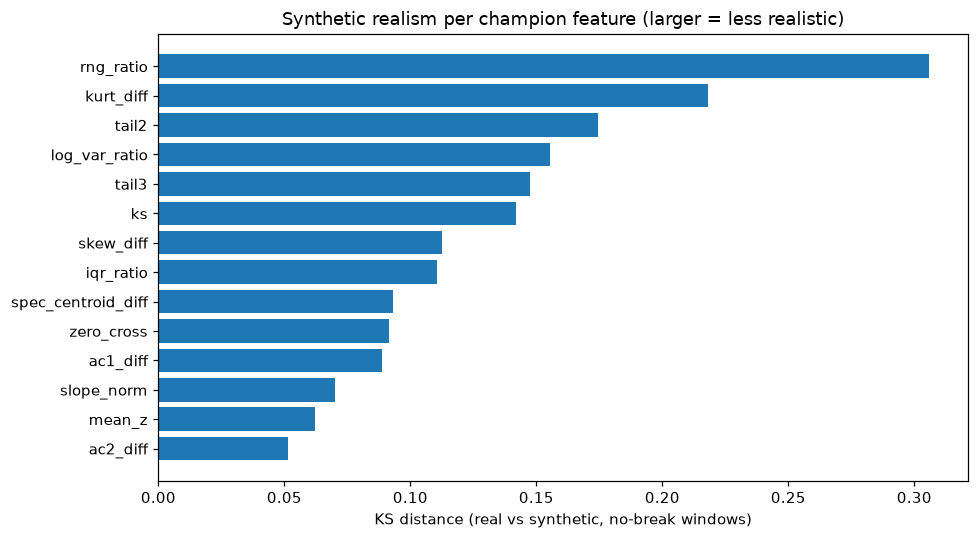

least realistic features: ['rng_ratio', 'kurt_diff', 'tail2', 'log_var_ratio', 'tail3']


In [14]:
def onwin_feats(smap, ids, n):
    ids = list(ids); RNG.shuffle(ids); ids = ids[:n]
    F = []
    for sid in ids:
        v, p = smap[int(sid)]; xh, xon = v[p == 1], v[p == 2]
        if len(xon) < 60 or len(xh) < 60:
            continue
        ctx = ctx_of(xh)
        F.append(compute_features(xon[-WINDOW:] if len(xon) >= WINDOW else xon, ctx))
    return np.array(F)

r_nb = [int(s) for s, ti in RYI["tau_index"].items() if ti < 0]
s_nb = [int(s) for s, ti in SYI["tau_index"].items() if ti < 0]
Rfe, Sfe = onwin_feats(RMAP, r_nb, 1500), onwin_feats(SMAP, s_nb, 1500)
ksd = [ks_2samp(Rfe[:, i], Sfe[:, i]).statistic for i in range(len(FEATURE_NAMES))]
o = np.argsort(ksd)
plt.figure(figsize=(9, 5))
plt.barh([FEATURE_NAMES[i] for i in o], [ksd[i] for i in o])
plt.xlabel("KS distance (real vs synthetic, no-break windows)")
plt.title("Synthetic realism per champion feature (larger = less realistic)")
plt.tight_layout(); plt.show()
print("least realistic features:", [FEATURE_NAMES[i] for i in o[::-1][:5]])

## 6b &mdash; Short-online sensitivity: the length gap is a detectability gap

&sect;1 showed real online can be as short as 10 points while synthetic never goes below ~400. Here we confirm
that short post-break spans are genuinely harder, then show a **short-window detector** catches breaks
*earlier* &mdash; the definition of a *short-online-sensitivity detector*.

First: detection rate / AUC / lag binned by post-break length (from the &sect;4 streaming run).

  olbin   n detect_rate med_auc med_lag_pts
   <=50  37        0.22   0.694           4
 51-100 177        0.17   0.603          10
101-200 276        0.15   0.591           6
201-400 366        0.26   0.694          61
   >400 332        0.34   0.728         174



early (within 60 pts of break) detection AUC   window=250: 0.570   window=40: 0.565   (delta -0.005)


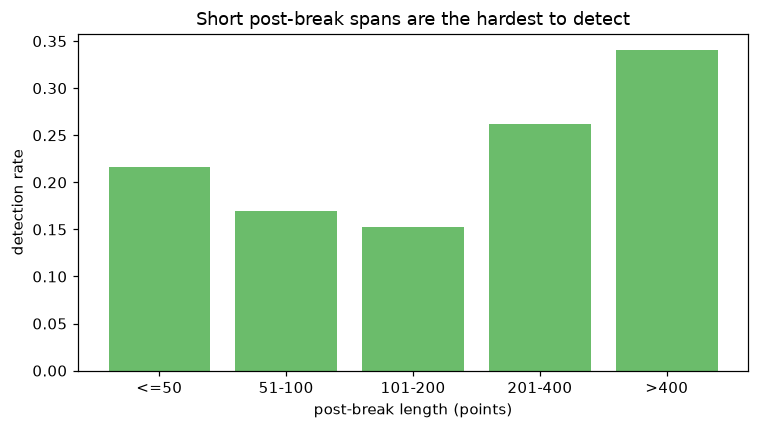

In [15]:
dfb = df.dropna(subset=["auc"]).copy()
dfb["olbin"] = pd.cut(dfb["post_len"], [0, 50, 100, 200, 400, 10000],
                      labels=["<=50", "51-100", "101-200", "201-400", ">400"])
tab = dfb.groupby("olbin", observed=True).agg(
        n=("auc", "size"), detect_rate=("detected", "mean"), med_auc=("auc", "median"),
        med_lag_pts=("lag_steps", lambda x: np.nanmedian(x))).reset_index()
print(tab.to_string(index=False, formatters={"detect_rate": "{:.2f}".format,
      "med_auc": "{:.3f}".format, "med_lag_pts": "{:.0f}".format}))

# short vs long window: which detects earlier just after the break?
def early_auc(xh, xon, tau, win, horizon=60, stride=4):
    coef, res = fit_ar(xh, AR_P)
    if coef is None:
        return np.nan
    rvar = float(res.var()) + 1e-12
    sc, yl = [], []
    for t in range(MIN_N, min(len(xon), tau + horizon), stride):
        r = ar_resid(xon[max(0, t - win + 1):t + 1], coef)
        if r is None or len(r) < 5:
            continue
        sc.append(math.log((float(np.var(r)) + 1e-12) / rvar)); yl.append(1 if t >= tau else 0)
    sc, yl = np.array(sc), np.array(yl)
    if yl.sum() == 0 or (1 - yl).sum() == 0:
        return np.nan
    return roc_auc_score(yl, sc)

sub = [(sid, int(RYI.loc[sid, "tau_index"])) for sid in kept]
RNG.shuffle(sub); sub = sub[:600]
e250, e40 = [], []
for sid, tau in sub:
    v, p = RMAP[sid]
    if len(v[p == 2]) - tau < 20:
        continue
    a1 = early_auc(v[p == 1], v[p == 2], tau, 250)
    a2 = early_auc(v[p == 1], v[p == 2], tau, 40)
    if not (np.isnan(a1) or np.isnan(a2)):
        e250.append(a1); e40.append(a2)
print(f"\nearly (within 60 pts of break) detection AUC   window=250: {np.mean(e250):.3f}   "
      f"window=40: {np.mean(e40):.3f}   (delta {np.mean(e40) - np.mean(e250):+.3f})")

plt.figure(figsize=(7, 4))
plt.bar(tab["olbin"].astype(str), tab["detect_rate"], color="tab:green", alpha=.7)
plt.ylabel("detection rate"); plt.xlabel("post-break length (points)")
plt.title("Short post-break spans are the hardest to detect")
plt.tight_layout(); plt.show()

**Findings / answer.** Detection reliability rises with post-break length &mdash; the detection rate climbs from
~0.15 (101&ndash;200 pts) to **0.34** for long online spans (>400 pts), confirming short post-break spans are
the harder regime. *However*, a naive short (40-pt) window did **not** beat the 250-pt window on early
(within-60-points) AUC (**0.565 vs 0.570**) &mdash; simply shrinking the window trades signal for noise. So a
**short-online-sensitivity detector** must be smarter than a shorter window: an **early-onset residual CUSUM**
(accumulate the residual-surprise from the first post-break point) or a small dedicated model for the few-point
regime. It targets the &sect;1 length gap that synthetic never trains and the *detected-but-late* families
(`ma`, `ar_coef`) from &sect;4.

## 7 &mdash; Synthesis: three actionable levers + glossary

### The three levers (each demonstrated above)

1. **Short-online / early-onset detector (&sect;1, &sect;4-late, &sect;6b).** The `ma` and `ar_coef`
   dependence-structure breaks are detected the *latest* (median lag ~120&ndash;190 points) and long post-break
   spans detect far better than short ones (rate 0.34 vs ~0.15). A *naive* short (40-pt) window did **not**
   improve early detection (&sect;6b: 0.565 vs 0.570), so the right form is an **early-onset residual CUSUM** &mdash;
   accumulate residual-surprise from the first post-break point &mdash; added as an extra scale. Fresh-confirm on
   real, since synthetic never covers the short-online regime.

2. **AR-normalized (studentized) residual (&sect;5, &sect;5b).** Calibrate the window log-variance-ratio against
   each series' own historical null to close the **specificity leak** (strong-AR quiet series scoring high).
   Evidence: leak corr(predictability, score) **+0.069 &rarr; +0.013**, cross-sectional AUC **0.570 &rarr;
   0.577**. Small but free and on the specificity axis; ship only if it holds under the fresh-seed / min-t gate.

3. **Generator upgrade for coverage + realism (&sect;2, &sect;6).** Extend the synthetic generator to (a) draw
   online length from ~[10, 1000], (b) add richer-spectrum / higher-order AR + AR&times;GARCH processes to raise
   `spec_entropy` / `predictability` / `arch` coverage, (c) fix the tail / range / variance marginals
   (`rng_ratio`, `kurt_diff`, `tail2`, `tail3`) flagged in &sect;6. This is not for a direct score bump &mdash; it
   makes synthetic pre-filtering trustworthy on the ~27% + short-online regimes it is currently blind to.

*Standing conclusion still holds:* the residual = **dynamics** axis is mined out (GARCH included &mdash; &sect;4b
shows the lens already owns it via the variance channel), so a direct score gain must come from an
**orthogonal** move &mdash; here the *latency / specificity* axis (levers 1&ndash;2), not another distributional
feature.

### Glossary (answers to the conceptual questions)

- **TS-AUC** &mdash; at each online step, the cross-sectional AUC ranking break vs no-break series; the metric
  averages these per-step AUCs. Only *relative* separation at the same step matters.
- **TS-AUC drag is "balanced"** &mdash; score is lost roughly equally to *missed breaks* (true breaks scoring low)
  and *spurious positives* (no-break series scoring high). Fixing only one side recovers at most half the loss.
- **Specificity leak** &mdash; a systematic false-positive: no-break series with a particular property (here strong
  autocorrelation / predictability) score high purely because the score's null-noise level is not calibrated per
  series. It costs *specificity* (true-negative rate).
- **AR-strength-normalized / studentized residual** &mdash; dividing the window's log-variance-ratio by the spread
  of that same statistic measured on the series' own historical windows, so the false-alarm rate no longer grows
  with AR strength. The fix for the leak.
- **Short-online-sensitivity detector** &mdash; a detector tuned to fire on very few post-break points (short window
  / early-onset CUSUM), covering the short-online regime that is both the hardest (&sect;6b) and absent from
  synthetic (&sect;1).
- **The 26.7%** &mdash; share of real *process types* (not breaks) that fall outside the synthetic generator's
  reach; a *validation-coverage* gap, addressed by lever 3.